<a href="https://colab.research.google.com/github/SaloMunoz1106/taller5-series-temporales/blob/main/S21_Taller5_Series_Temporales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# S21 · Taller 5 · Series temporales financieras y análisis de portafolios
**Lenguajes de Programación · Ingeniería Financiera · ITM**

Este cuaderno tiene dos partes:

* **Parte A – Práctica guiada:** los siete conceptos de la sesión aplicados a Apple (AAPL), Coca-Cola (KO) y el ETF SPY.
* **Parte B – Reto final:** las siete etapas del análisis aplicadas a mi portafolio personal (**Set 4**: META, MS, OXY, LLY y MCD) frente al mercado (SPY), con datos de 2021 a 2025.

**Convenciones:** rendimiento simple $r_t = P_t/P_{t-1}-1$; 252 días de negociación por año; tasa libre de riesgo = 0 para el ratio de Sharpe.

In [41]:
%pip install -q yfinance
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
DIAS = 252
INICIO, FIN = "2021-01-01", "2026-01-01"   # FIN es exclusivo: llega hasta el 31-dic-2025

## Parte A · Práctica guiada (AAPL, KO y SPY)

### A1. Serie temporal: índice, valor y frecuencia

Índice tipo fecha: True | ordenado: True
Observaciones diarias: 1255 | del 2021-01-04 al 2025-12-31
Observaciones mensuales: 60


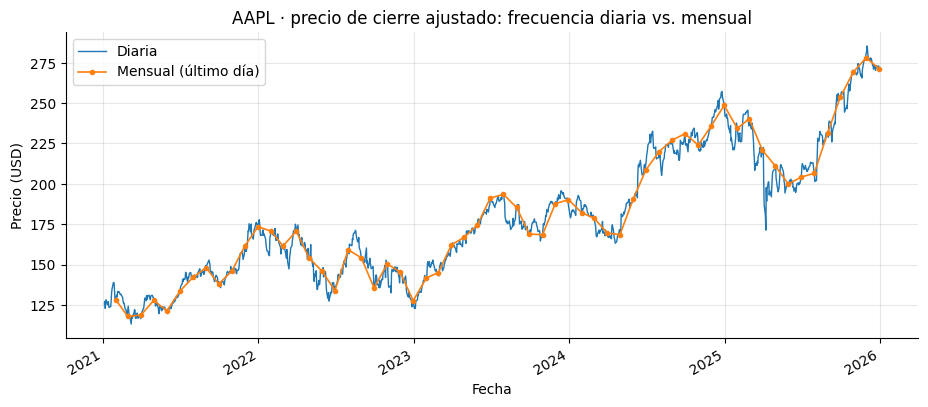

In [42]:
tick_a = ["AAPL", "KO", "SPY"]
datos_a = yf.download(tick_a, start=INICIO, end=FIN, auto_adjust=True, progress=False)
precios_a = datos_a["Close"][tick_a].dropna()          # solo fechas comunes, sin faltantes
print("Índice tipo fecha:", isinstance(precios_a.index, pd.DatetimeIndex), "| ordenado:", precios_a.index.is_monotonic_increasing)
print("Observaciones diarias:", len(precios_a), "| del", precios_a.index[0].date(), "al", precios_a.index[-1].date())

aapl = precios_a["AAPL"]
mensual = aapl.resample("ME").last()                   # cambio de frecuencia a mensual
print("Observaciones mensuales:", len(mensual))

fig, ax = plt.subplots()
aapl.plot(ax=ax, label="Diaria", lw=1)
mensual.plot(ax=ax, label="Mensual (último día)", marker="o", ms=3, lw=1.2)
ax.set(title="AAPL · precio de cierre ajustado: frecuencia diaria vs. mensual", xlabel="Fecha", ylabel="Precio (USD)")
ax.legend(); plt.show()

**Lectura:** la serie diaria tiene ~252 observaciones por año (no 365) porque excluye fines de semana y festivos; la mensual simplifica la lectura pero oculta los movimientos internos de cada mes.

### A2. Rendimientos

Ticker     AAPL       KO      SPY
mean    0.00077  0.00039  0.00060
std     0.01755  0.00998  0.01078
min    -0.09246 -0.06963 -0.05854
max     0.15329  0.04725  0.10502


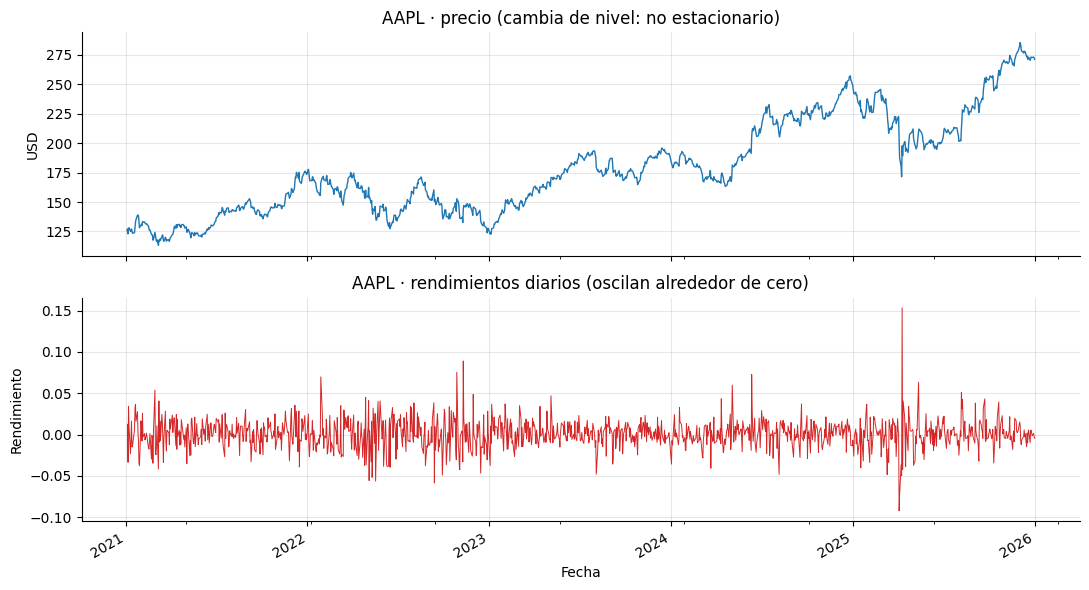

Autocorrelación lag-1 de los rendimientos AAPL: 0.0124
Autocorrelación lag-1 de los rendimientos² (volatilidad): 0.1747


In [43]:
rend_a = precios_a.pct_change().dropna()               # P_t / P_(t-1) - 1
print(rend_a.describe().loc[["mean", "std", "min", "max"]].round(5))

fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
aapl.plot(ax=axs[0], lw=1); axs[0].set(title="AAPL · precio (cambia de nivel: no estacionario)", ylabel="USD")
rend_a["AAPL"].plot(ax=axs[1], lw=.7, color="tab:red")
axs[1].set(title="AAPL · rendimientos diarios (oscilan alrededor de cero)", xlabel="Fecha", ylabel="Rendimiento")
plt.tight_layout(); plt.show()

print("Autocorrelación lag-1 de los rendimientos AAPL:", round(rend_a["AAPL"].autocorr(1), 4))
print("Autocorrelación lag-1 de los rendimientos² (volatilidad):", round((rend_a["AAPL"]**2).autocorr(1), 4))

**Lectura:** el precio cambia de nivel (no es estacionario), mientras que los rendimientos oscilan alrededor de cero. La autocorrelación de los rendimientos es cercana a cero (el rendimiento de hoy no anticipa linealmente el de mañana), pero la de los rendimientos al cuadrado es positiva: la volatilidad se agrupa.

### A3. Tendencia y promedio móvil

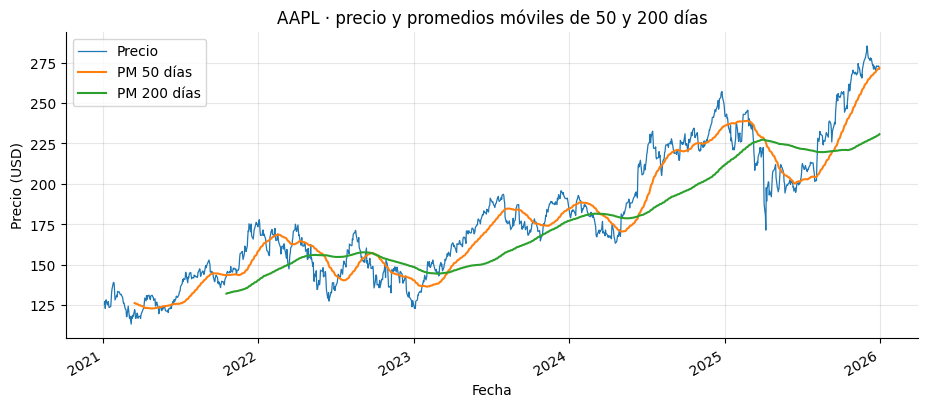

Días sin PM50: 49 | sin PM200: 199
Precio sobre su PM50 el 60.0 % de los días


In [44]:
pm50 = aapl.rolling(50).mean()
pm200 = aapl.rolling(200).mean()
fig, ax = plt.subplots()
aapl.plot(ax=ax, lw=.9, label="Precio"); pm50.plot(ax=ax, label="PM 50 días"); pm200.plot(ax=ax, label="PM 200 días")
ax.set(title="AAPL · precio y promedios móviles de 50 y 200 días", xlabel="Fecha", ylabel="Precio (USD)"); ax.legend(); plt.show()
print("Días sin PM50:", pm50.isna().sum(), "| sin PM200:", pm200.isna().sum())
print("Precio sobre su PM50 el", round((aapl > pm50)[pm50.notna()].mean()*100, 1), "% de los días")

### A4. Volatilidad

Volatilidad anual:
 Ticker
AAPL    27.86 %
KO      15.83 %
SPY     17.11 %
dtype: object


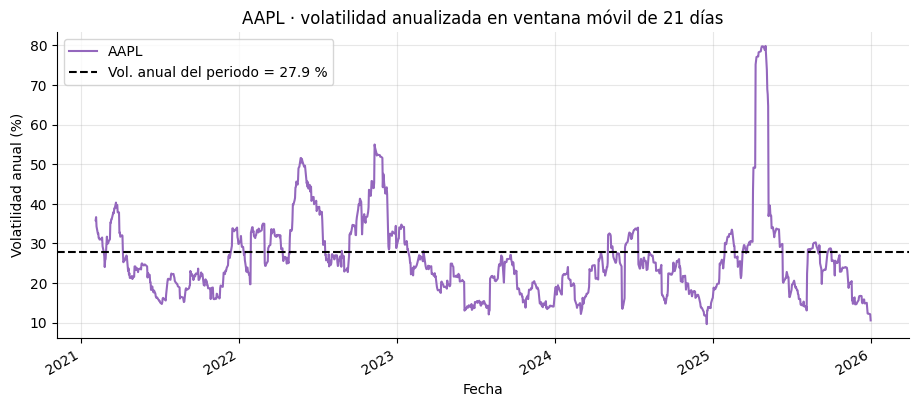

In [45]:
vol_a = rend_a.std() * np.sqrt(DIAS)
print("Volatilidad anual:\n", (vol_a*100).round(2).astype(str) + " %")
vol_mov_a = rend_a["AAPL"].rolling(21).std() * np.sqrt(DIAS)
fig, ax = plt.subplots()
(vol_mov_a*100).plot(ax=ax, color="tab:purple")
ax.axhline(vol_a["AAPL"]*100, color="k", ls="--", label=f"Vol. anual del periodo = {vol_a['AAPL']*100:.1f} %")
ax.set(title="AAPL · volatilidad anualizada en ventana móvil de 21 días", xlabel="Fecha", ylabel="Volatilidad anual (%)"); ax.legend(); plt.show()

### A5. Rendimiento acumulado

Rendimiento acumulado:
 Ticker
AAPL    115.81 %
KO       54.01 %
SPY      98.08 %
Name: 2025-12-31 00:00:00, dtype: object


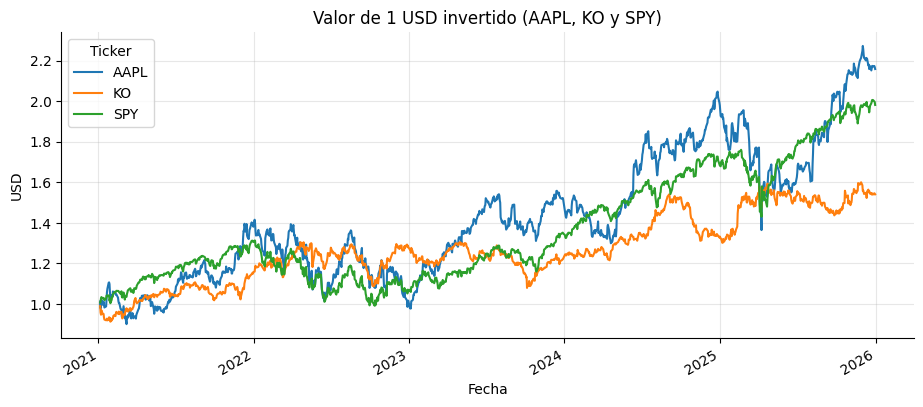

In [46]:
W_a = (1 + rend_a).cumprod()                           # valor de 1 USD invertido
print("Rendimiento acumulado:\n", ((W_a.iloc[-1]-1)*100).round(2).astype(str) + " %")
fig, ax = plt.subplots()
W_a.plot(ax=ax)
ax.set(title="Valor de 1 USD invertido (AAPL, KO y SPY)", xlabel="Fecha", ylabel="USD"); plt.show()

### A6. Máxima caída (drawdown)

Máxima caída:
 Ticker
AAPL    -33.36 %
KO      -17.27 %
SPY      -24.5 %
dtype: object


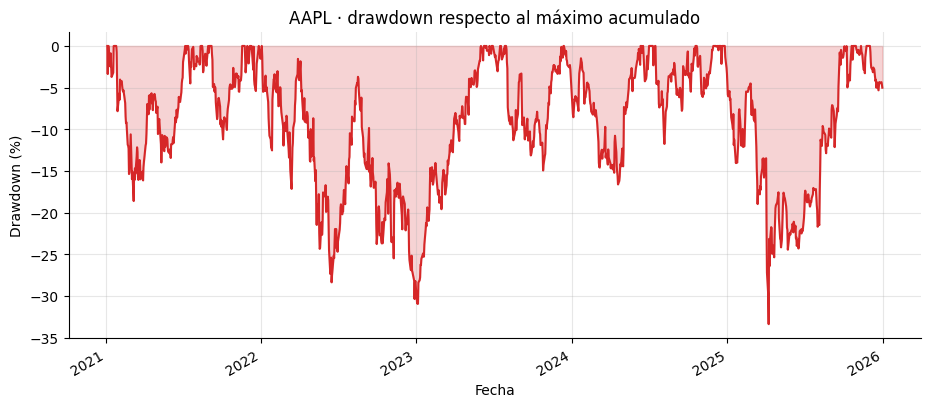

In [47]:
dd_a = W_a / W_a.cummax() - 1
print("Máxima caída:\n", (dd_a.min()*100).round(2).astype(str) + " %")
fig, ax = plt.subplots()
(dd_a["AAPL"]*100).plot(ax=ax, color="tab:red"); ax.fill_between(dd_a.index, dd_a["AAPL"]*100, 0, color="tab:red", alpha=.2)
ax.set(title="AAPL · drawdown respecto al máximo acumulado", xlabel="Fecha", ylabel="Drawdown (%)"); plt.show()

### A7. Correlación y diversificación (AAPL + KO, 50/50)

In [48]:
r2 = rend_a[["AAPL", "KO"]]
corr = r2.corr().loc["AAPL", "KO"]
rp = r2.dot([0.5, 0.5])
vol_p = rp.std() * np.sqrt(DIAS)
vol_prom = 0.5*vol_a["AAPL"] + 0.5*vol_a["KO"]
print(f"Correlación AAPL-KO: {corr:.3f}")
print(f"Vol. promedio ponderada: {vol_prom*100:.2f} % | Vol. del portafolio: {vol_p*100:.2f} % | reducción: {(vol_prom-vol_p)*100:.2f} pp")

Correlación AAPL-KO: 0.271
Vol. promedio ponderada: 21.85 % | Vol. del portafolio: 17.79 % | reducción: 4.06 pp


---
## Parte B · Reto final: mi portafolio (Set 4) frente al mercado

**Set 4:** Tecnología **META** · Financiero **MS** · Energía **OXY** · Salud **LLY** · Consumo **MCD**, con **SPY** como referencia del mercado.

In [49]:
mis_acciones = ["META", "MS", "OXY", "LLY", "MCD"]
mercado = "SPY"

# Pesos: suman 1 y ninguno supera 0,40 (reparto igualitario entre los cinco sectores)
pesos = pd.Series({"META": 0.20, "MS": 0.20, "OXY": 0.20, "LLY": 0.20, "MCD": 0.20})
assert abs(pesos.sum() - 1) < 1e-9, "Los pesos deben sumar 1"
assert (pesos <= 0.40).all(), "Ningún peso puede superar 0,40"
assert list(pesos.index) == mis_acciones
print(pesos)

META    0.2
MS      0.2
OXY     0.2
LLY     0.2
MCD     0.2
dtype: float64


### Descarga y preparación de los datos (2021–2025)

In [50]:
datos = yf.download(mis_acciones + [mercado], start=INICIO, end=FIN, auto_adjust=True, progress=False)
precios = datos["Close"][mis_acciones + [mercado]].dropna()   # fechas comunes, sin faltantes
assert precios.index.is_monotonic_increasing
print(f"{len(precios)} días de negociación | {precios.index[0].date()} → {precios.index[-1].date()}")
precios.tail()

1255 días de negociación | 2021-01-04 → 2025-12-31


Ticker,META,MS,OXY,LLY,MCD,SPY
Date,,,,,,
2025-12-24,665.835876,178.704727,39.446930,1071.801880,307.306061,685.029480
2025-12-26,661.586853,178.921173,39.299000,1072.568237,304.707001,684.960022
2025-12-29,656.998657,177.022461,39.851261,1073.543457,302.598358,682.519043
2025-12-30,664.239990,176.176407,40.886742,1074.558716,302.107971,681.685608
2025-12-31,658.395020,174.651535,40.551441,1069.513062,299.754120,676.635010


In [51]:
rend = precios.pct_change().dropna()
rend_p = rend[mis_acciones].dot(pesos)       # rendimiento diario del portafolio
rend_m = rend[mercado]                        # rendimiento diario del mercado
W_p = (1 + rend_p).cumprod()                  # valor de 1 USD en el portafolio
W_m = (1 + rend_m).cumprod()                  # valor de 1 USD en SPY

### Etapa 1 · Serie temporal: ¿cuál fue la trayectoria del precio?

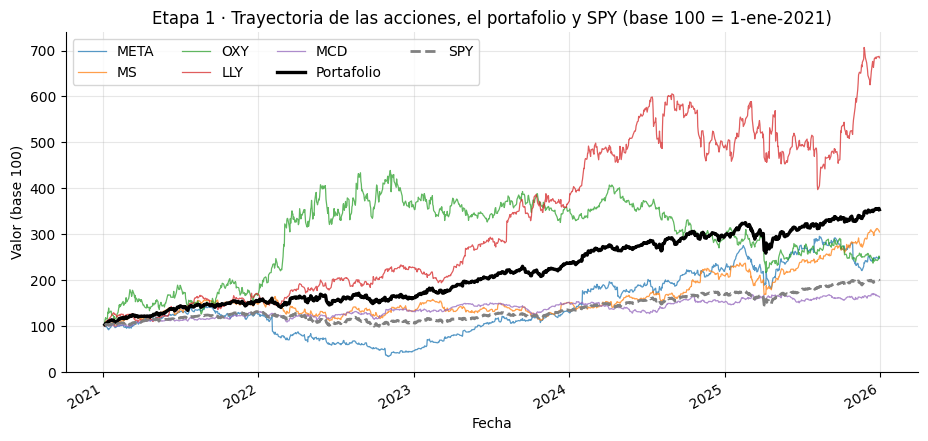

Portafolio (base 100): inicio 102.73 | máximo 355.94 (2025-12-30) | mínimo 102.73 (2021-01-05) | cierre 353.23
Precio inicial → final de cada acción (USD):
Date    2021-01-04  2025-12-31
Ticker                        
META        266.39      658.40
MS           57.31      174.65
OXY          16.22       40.55
LLY         156.30     1069.51
MCD         183.93      299.75


In [52]:
base100 = precios / precios.iloc[0] * 100
port100 = W_p * 100
fig, ax = plt.subplots(figsize=(11, 5))
base100[mis_acciones].plot(ax=ax, lw=.9, alpha=.75)
port100.plot(ax=ax, color="black", lw=2.4, label="Portafolio")
(W_m*100).plot(ax=ax, color="gray", lw=2, ls="--", label="SPY")
ax.set(title="Etapa 1 · Trayectoria de las acciones, el portafolio y SPY (base 100 = 1-ene-2021)", xlabel="Fecha", ylabel="Valor (base 100)")
ax.legend(ncol=4); plt.show()

print(f"Portafolio (base 100): inicio {port100.iloc[0]:.2f} | máximo {port100.max():.2f} ({port100.idxmax().date()}) | "
      f"mínimo {port100.min():.2f} ({port100.idxmin().date()}) | cierre {port100.iloc[-1]:.2f}")
print("Precio inicial → final de cada acción (USD):")
print(precios[mis_acciones].iloc[[0, -1]].round(2).T.rename(columns=lambda c: str(c.date())))

### Etapa 2 · Rendimientos: ¿qué tan grandes fueron los movimientos diarios?

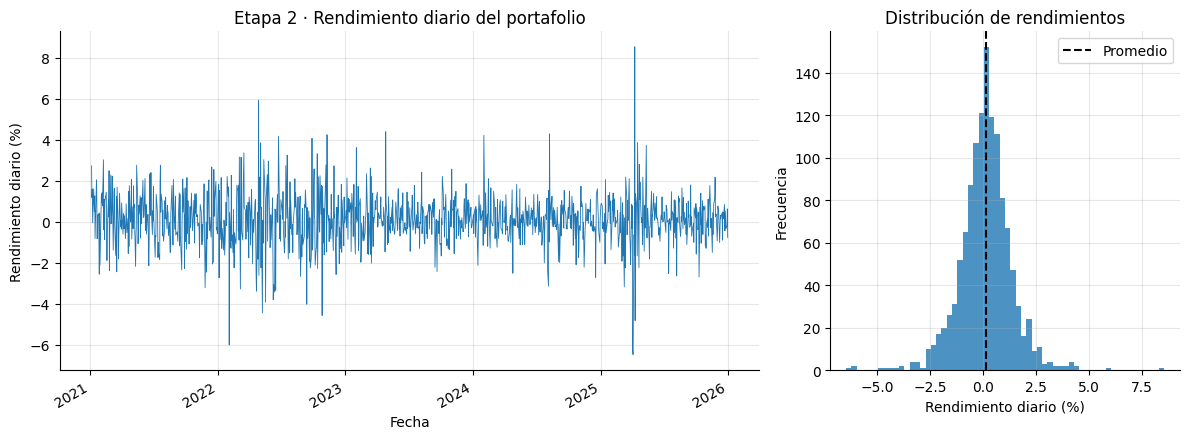

Rendimiento diario promedio: 0.1083 % | desviación diaria: 1.235 %
Mejor día: +8.54 % (2025-04-09) | Peor día: -6.47 % (2025-04-04)
Autocorrelación lag-1 de rendimientos: -0.022  | de rendimientos²: +0.191


In [53]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [2, 1]})
(rend_p*100).plot(ax=axs[0], lw=.6, color="tab:blue", label="Portafolio")
axs[0].set(title="Etapa 2 · Rendimiento diario del portafolio", xlabel="Fecha", ylabel="Rendimiento diario (%)")
axs[1].hist(rend_p*100, bins=60, color="tab:blue", alpha=.8)
axs[1].axvline(rend_p.mean()*100, color="k", ls="--", label="Promedio")
axs[1].set(title="Distribución de rendimientos", xlabel="Rendimiento diario (%)", ylabel="Frecuencia"); axs[1].legend()
plt.tight_layout(); plt.show()

print(f"Rendimiento diario promedio: {rend_p.mean()*100:.4f} % | desviación diaria: {rend_p.std()*100:.3f} %")
print(f"Mejor día: {rend_p.max()*100:+.2f} % ({rend_p.idxmax().date()}) | Peor día: {rend_p.min()*100:+.2f} % ({rend_p.idxmin().date()})")
print(f"Autocorrelación lag-1 de rendimientos: {rend_p.autocorr(1):+.3f}  | de rendimientos²: {(rend_p**2).autocorr(1):+.3f}")

### Etapa 3 · Tendencia: ¿hacia dónde se movió el portafolio?

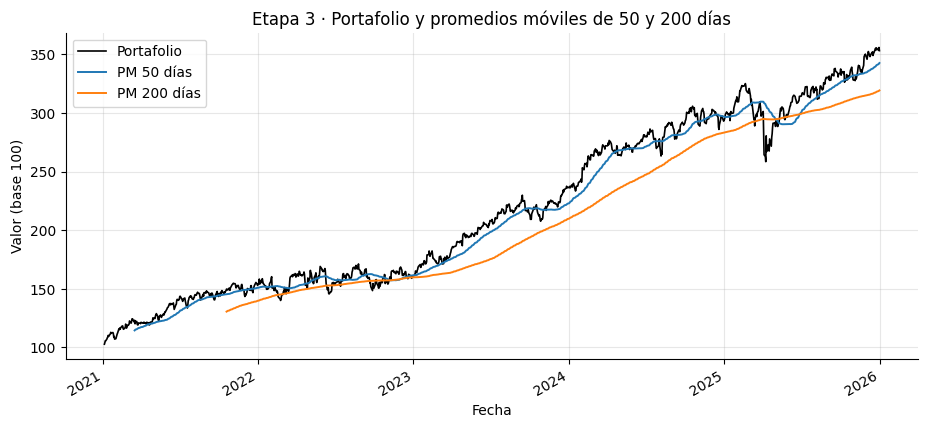

Portafolio por encima de su PM50 el 77.2 % de los días y de su PM200 el 92.8 %
Último cierre: 353.23 | PM50: 342.67 | PM200: 319.29 → tendencia reciente creciente


In [54]:
pm50 = port100.rolling(50).mean()
pm200 = port100.rolling(200).mean()
fig, ax = plt.subplots(figsize=(11, 4.8))
port100.plot(ax=ax, lw=1.2, color="black", label="Portafolio")
pm50.plot(ax=ax, lw=1.4, label="PM 50 días"); pm200.plot(ax=ax, lw=1.4, label="PM 200 días")
ax.set(title="Etapa 3 · Portafolio y promedios móviles de 50 y 200 días", xlabel="Fecha", ylabel="Valor (base 100)"); ax.legend(); plt.show()

sobre50 = (port100 > pm50)[pm50.notna()].mean()*100
sobre200 = (port100 > pm200)[pm200.notna()].mean()*100
print(f"Portafolio por encima de su PM50 el {sobre50:.1f} % de los días y de su PM200 el {sobre200:.1f} %")
print(f"Último cierre: {port100.iloc[-1]:.2f} | PM50: {pm50.iloc[-1]:.2f} | PM200: {pm200.iloc[-1]:.2f} → tendencia reciente "
      + ("creciente" if port100.iloc[-1] > pm50.iloc[-1] else "decreciente"))

### Etapa 4 · Volatilidad: ¿cuánto riesgo asumió?

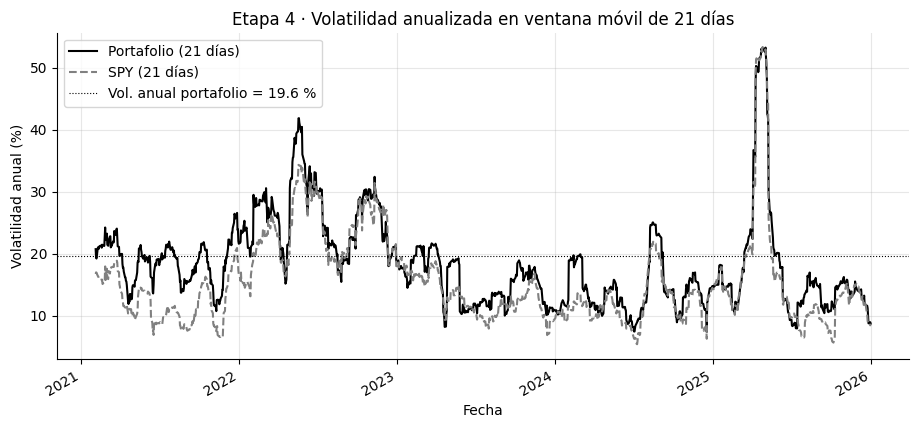

Volatilidad anual → Portafolio: 19.60 % | SPY: 17.11 %
Volatilidad anual por acción (%): {'META': 43.41, 'MS': 28.32, 'OXY': 42.33, 'LLY': 31.96, 'MCD': 17.17}
Pico de volatilidad móvil del portafolio: 53.3 % (2025-04-25) | mínimo: 7.4 % (2024-12-17)


In [55]:
vol_p = rend_p.std() * np.sqrt(DIAS)
vol_m = rend_m.std() * np.sqrt(DIAS)
vol_ind = rend[mis_acciones].std() * np.sqrt(DIAS)
vm_p = rend_p.rolling(21).std() * np.sqrt(DIAS)
vm_m = rend_m.rolling(21).std() * np.sqrt(DIAS)

fig, ax = plt.subplots(figsize=(11, 4.8))
(vm_p*100).plot(ax=ax, color="black", label="Portafolio (21 días)")
(vm_m*100).plot(ax=ax, color="gray", ls="--", label="SPY (21 días)")
ax.axhline(vol_p*100, color="black", lw=.8, ls=":", label=f"Vol. anual portafolio = {vol_p*100:.1f} %")
ax.set(title="Etapa 4 · Volatilidad anualizada en ventana móvil de 21 días", xlabel="Fecha", ylabel="Volatilidad anual (%)"); ax.legend(); plt.show()

print(f"Volatilidad anual → Portafolio: {vol_p*100:.2f} % | SPY: {vol_m*100:.2f} %")
print("Volatilidad anual por acción (%):", (vol_ind*100).round(2).to_dict())
print(f"Pico de volatilidad móvil del portafolio: {vm_p.max()*100:.1f} % ({vm_p.idxmax().date()}) | mínimo: {vm_p.min()*100:.1f} % ({vm_p.idxmin().date()})")

### Etapa 5 · Rendimiento acumulado: ¿cuánto rindió?

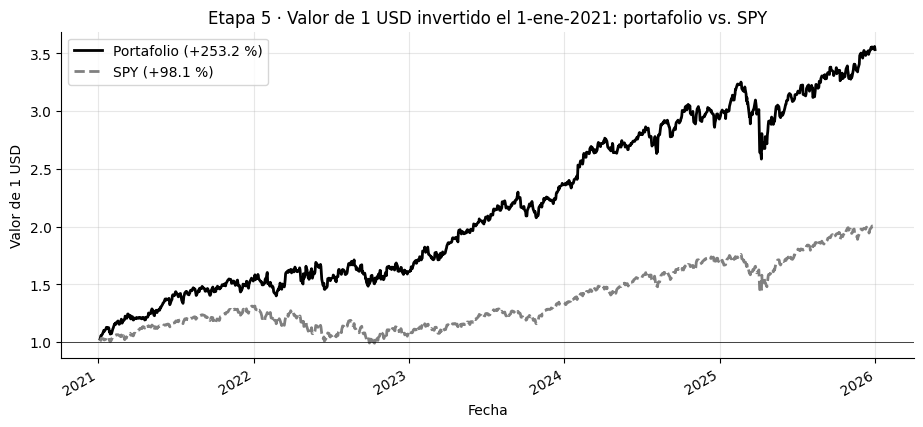

Rendimiento acumulado → Portafolio: +253.23 % | SPY: +98.08 %
Rendimiento anualizado (CAGR) → Portafolio: 28.87 % | SPY: 14.72 %
Rendimiento acumulado por acción (%): {'META': 147.2, 'MS': 204.8, 'OXY': 150.1, 'LLY': 584.3, 'MCD': 63.0}


In [56]:
rc_p = W_p.iloc[-1] - 1
rc_m = W_m.iloc[-1] - 1
anios = len(rend_p) / DIAS
cagr_p = W_p.iloc[-1]**(1/anios) - 1
cagr_m = W_m.iloc[-1]**(1/anios) - 1
rc_ind = (1 + rend[mis_acciones]).cumprod().iloc[-1] - 1

fig, ax = plt.subplots(figsize=(11, 4.8))
W_p.plot(ax=ax, color="black", lw=2, label=f"Portafolio ({rc_p*100:+.1f} %)")
W_m.plot(ax=ax, color="gray", lw=2, ls="--", label=f"SPY ({rc_m*100:+.1f} %)")
ax.axhline(1, color="k", lw=.5)
ax.set(title="Etapa 5 · Valor de 1 USD invertido el 1-ene-2021: portafolio vs. SPY", xlabel="Fecha", ylabel="Valor de 1 USD"); ax.legend(); plt.show()

print(f"Rendimiento acumulado → Portafolio: {rc_p*100:+.2f} % | SPY: {rc_m*100:+.2f} %")
print(f"Rendimiento anualizado (CAGR) → Portafolio: {cagr_p*100:.2f} % | SPY: {cagr_m*100:.2f} %")
print("Rendimiento acumulado por acción (%):", (rc_ind*100).round(1).to_dict())

### Etapa 6 · Máxima caída: ¿cuánto llegó a perder?

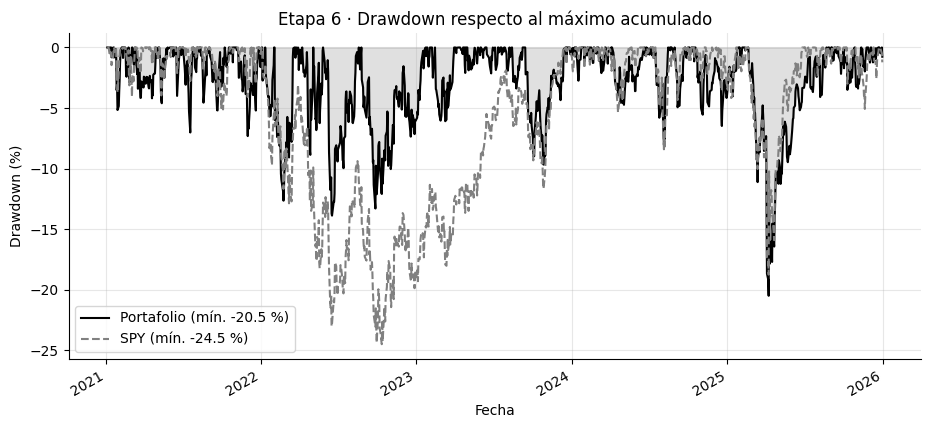

Máxima caída del portafolio: -20.50 % (pico 2025-02-19 → valle 2025-04-08)
Máxima caída de SPY:         -24.50 % (pico 2022-01-03 → valle 2022-10-12)
Recuperación del máximo previo (portafolio): 2025-08-22


In [57]:
dd_p = W_p / W_p.cummax() - 1
dd_m = W_m / W_m.cummax() - 1
mdd_p, mdd_m = dd_p.min(), dd_m.min()
fecha_mdd_p, fecha_mdd_m = dd_p.idxmin(), dd_m.idxmin()
pico_p = W_p.loc[:fecha_mdd_p].idxmax()
pico_m = W_m.loc[:fecha_mdd_m].idxmax()

fig, ax = plt.subplots(figsize=(11, 4.8))
(dd_p*100).plot(ax=ax, color="black", label=f"Portafolio (mín. {mdd_p*100:.1f} %)")
(dd_m*100).plot(ax=ax, color="gray", ls="--", label=f"SPY (mín. {mdd_m*100:.1f} %)")
ax.fill_between(dd_p.index, dd_p*100, 0, color="black", alpha=.12)
ax.set(title="Etapa 6 · Drawdown respecto al máximo acumulado", xlabel="Fecha", ylabel="Drawdown (%)"); ax.legend(loc="lower left"); plt.show()

print(f"Máxima caída del portafolio: {mdd_p*100:.2f} % (pico {pico_p.date()} → valle {fecha_mdd_p.date()})")
print(f"Máxima caída de SPY:         {mdd_m*100:.2f} % (pico {pico_m.date()} → valle {fecha_mdd_m.date()})")
recup = dd_p.loc[fecha_mdd_p:]
rec = recup[recup >= 0]
print("Recuperación del máximo previo (portafolio):", rec.index[0].date() if len(rec) else "aún no recuperado al 31-dic-2025")

### Etapa 7 · Diversificación: ¿cuánto riesgo se redujo al combinar las acciones?

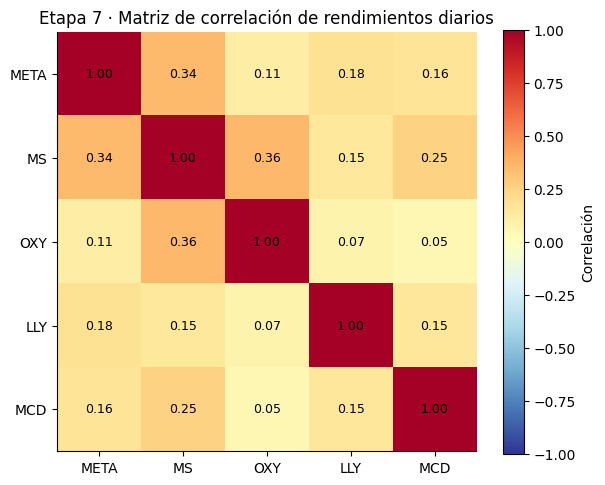

Correlación promedio entre pares: 0.183
Par más correlacionado: ('MS', 'OXY') = 0.355
Par menos correlacionado: ('OXY', 'MCD') = 0.050
Vol. promedio ponderada: 32.64 % | Vol. del portafolio: 19.60 % | reducción por diversificación: 13.04 pp (39.9 %)


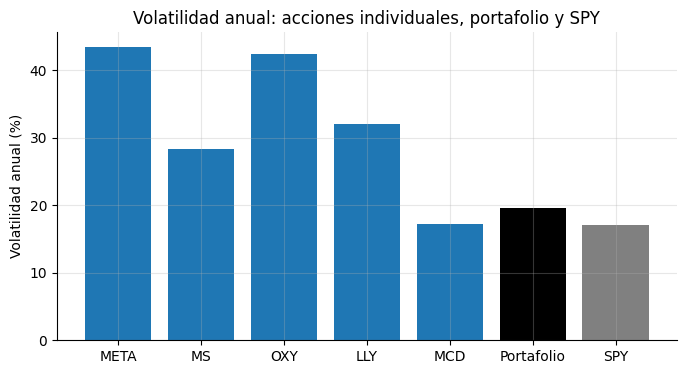

In [58]:
corr = rend[mis_acciones].corr()
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(corr, cmap="RdYlBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(5), mis_acciones); ax.set_yticks(range(5), mis_acciones)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax.set(title="Etapa 7 · Matriz de correlación de rendimientos diarios"); ax.grid(False)
plt.colorbar(im, ax=ax, label="Correlación"); plt.tight_layout(); plt.show()

vol_prom_pond = (pesos * vol_ind).sum()
corr_media = corr.values[np.triu_indices(5, 1)].mean()
print(f"Correlación promedio entre pares: {corr_media:.3f}")
print(f"Par más correlacionado: {corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().idxmax()} = {corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().max():.3f}")
print(f"Par menos correlacionado: {corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().idxmin()} = {corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().min():.3f}")
print(f"Vol. promedio ponderada: {vol_prom_pond*100:.2f} % | Vol. del portafolio: {vol_p*100:.2f} % | reducción por diversificación: {(vol_prom_pond-vol_p)*100:.2f} pp ({(1-vol_p/vol_prom_pond)*100:.1f} %)")

fig, ax = plt.subplots(figsize=(8, 4))
barras = pd.concat([vol_ind, pd.Series({"Portafolio": vol_p, "SPY": vol_m})])*100
ax.bar(barras.index, barras.values, color=["tab:blue"]*5 + ["black", "gray"])
ax.set(title="Volatilidad anual: acciones individuales, portafolio y SPY", ylabel="Volatilidad anual (%)"); plt.show()

## Comparación con el mercado: ratio de Sharpe y máxima caída

,Portafolio,SPY
Rend. acumulado (%),253.23,98.08
Rend. anual (%),27.29,15.20
Volatilidad anual (%),19.60,17.11
Sharpe (rf = 0),1.39,0.89
Máxima caída (%),-20.50,-24.50
Rend. anual / |Máx. caída|,1.33,0.62


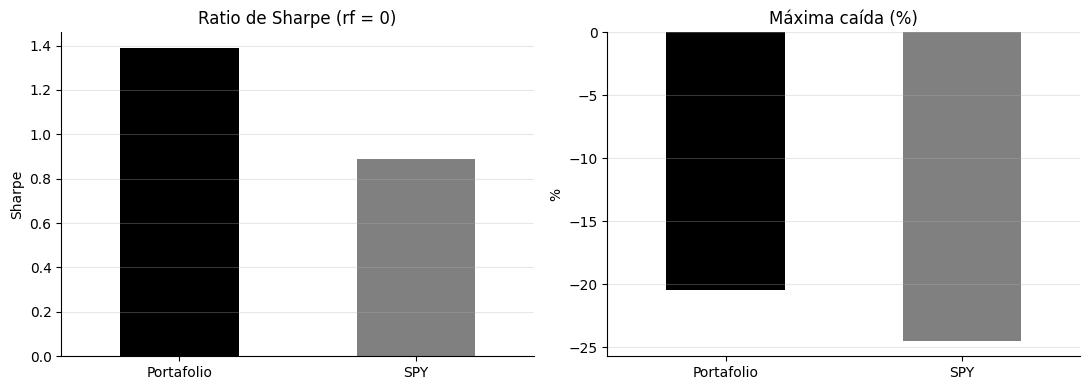

Sharpe portafolio = 1.39 vs SPY = 0.89 → el portafolio rindió más por unidad de riesgo


In [59]:
def metricas(r, W):
    ret_anual = r.mean() * DIAS                      # rendimiento anual (media diaria × 252)
    vol = r.std() * np.sqrt(DIAS)
    dd = (W / W.cummax() - 1).min()
    return pd.Series({"Rend. acumulado (%)": (W.iloc[-1]-1)*100,
                      "Rend. anual (%)": ret_anual*100,
                      "Volatilidad anual (%)": vol*100,
                      "Sharpe (rf = 0)": ret_anual/vol,
                      "Máxima caída (%)": dd*100,
                      "Rend. anual / |Máx. caída|": ret_anual/abs(dd)})
tabla = pd.DataFrame({"Portafolio": metricas(rend_p, W_p), "SPY": metricas(rend_m, W_m)}).round(2)
display(tabla)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
tabla.loc["Sharpe (rf = 0)"].plot.bar(ax=axs[0], color=["black", "gray"], rot=0)
axs[0].set(title="Ratio de Sharpe (rf = 0)", ylabel="Sharpe")
tabla.loc["Máxima caída (%)"].plot.bar(ax=axs[1], color=["black", "gray"], rot=0)
axs[1].set(title="Máxima caída (%)", ylabel="%")
for a in axs: a.grid(axis="x", alpha=0)
plt.tight_layout(); plt.show()

sh_p, sh_m = tabla.loc["Sharpe (rf = 0)", "Portafolio"], tabla.loc["Sharpe (rf = 0)", "SPY"]
print(f"Sharpe portafolio = {sh_p:.2f} vs SPY = {sh_m:.2f} → "
      + ("el portafolio rindió más por unidad de riesgo" if sh_p > sh_m else "SPY rindió más por unidad de riesgo"))

## Conclusión

Entre 2021 y 2025 mi portafolio igualmente ponderado (META, MS, OXY, LLY y MCD) rindió +253,2 % acumulado (28,9 % anual compuesto), frente a +98,1 % (14,7 % anual) de SPY: superó al mercado por más de 155 puntos porcentuales.

Ese mayor rendimiento vino con un poco más de riesgo total: la volatilidad anual fue 19,6 % frente a 17,1 % de SPY, con un pico de 53,3 % en abril de 2025 durante la turbulencia arancelaria.

Aun así, el rendimiento por unidad de riesgo fue claramente mayor: Sharpe de 1,39 para el portafolio frente a 0,89 para SPY (con tasa libre de riesgo igual a cero).

En pérdidas también salió mejor librado: su máxima caída fue -20,5 % (19-feb-2025 a 8-abr-2025) frente a -24,5 % de SPY (ene-oct de 2022), y recuperó su máximo previo el 22 de agosto de 2025.

La diversificación explica parte del resultado: la correlación promedio entre pares es solo 0,18 (OXY-MCD 0,05) y la volatilidad del portafolio (19,6 %) es 13 puntos menor que el promedio ponderado de las volatilidades individuales (32,6 %), es decir, un 39,9 % menos riesgo.

Como matiz, el resultado depende mucho de LLY (+584 %) y de un periodo favorable a META y MS; con solo cinco acciones hay riesgo de concentración y el pasado no garantiza el desempeño futuro.

En conclusión, dentro de esta muestra el portafolio ofreció más rendimiento, mejor Sharpe y menor caída máxima que el mercado, aunque con una volatilidad levemente superior.

---
### Verificación final

In [60]:
assert abs(pesos.sum() - 1) < 1e-9 and (pesos <= .40).all()
assert set(mis_acciones) == {"META", "MS", "OXY", "LLY", "MCD"}
print("✔ Set 4 + SPY | pesos válidos | 7 etapas + comparación ejecutadas sin errores")

✔ Set 4 + SPY | pesos válidos | 7 etapas + comparación ejecutadas sin errores
